# Campaign value estimate

Question: if a retention team can contact 10% of active customers, who should it contact and what could that be worth?

Assumptions. All of them are stated here, none are learned from this data:
- Churn rate by risk decile comes from the walk-forward test (Part 7), not from raw model scores, which are not calibrated.
- A customer who churns would have spent about what they spent per 90 days over the last 180 days. This is a proxy: churners cannot be observed spending, and they may have spent less than average.
- The campaign effect (share of would-be churners retained) is unknown. Scenarios of 5%, 10% and 20% are shown. A real value needs a randomized holdout test.
- No cost is assumed. The result is the break-even cost per contact, in revenue (not profit) terms.

In [1]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.db import query
from src.models.churn_models import load_data, walk_forward

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

data = load_data()
results, preds = walk_forward(data)
lr = preds[preds["model"] == "logistic regression"].copy()
print(len(lr), "test predictions over", lr["snapshot_date"].nunique(), "snapshots")

30814 test predictions over 10 snapshots


In [2]:
# Observed churn rate by risk decile. Customers are ranked within each snapshot,
# so every month contributes equally to each decile.
lr["rank_in_snapshot"] = lr.groupby("snapshot_date")["score"].rank(ascending=False, method="first")
lr["n_in_snapshot"] = lr.groupby("snapshot_date")["score"].transform("size")
lr["decile"] = np.ceil(10 * lr["rank_in_snapshot"] / lr["n_in_snapshot"]).astype(int)

pooled = lr.groupby("decile")["churned"].mean().rename("all_10_snapshots")
lull = (lr[lr["snapshot_date"].isin(pd.to_datetime(["2010-12-01", "2011-01-01"]))]
        .groupby("decile")["churned"].mean().rename("dec_jan_only"))
rates = pd.concat([pooled, lull], axis=1)
rates

,all_10_snapshots,dec_jan_only
decile,,
1,0.84,0.88
2,0.80,0.87
3,0.75,0.83
4,0.69,0.80
5,0.62,0.71
6,0.56,0.64
7,0.47,0.58
8,0.36,0.46
9,0.24,0.30


In [3]:
# Active customers at the scoring snapshot (10 Dec 2011) with a value proxy
scoring = query("""
SELECT s.customer_key, s.risk_score, s.risk_rank, s.risk_decile, c.spend_180d
FROM gold.customer_risk_scores s
JOIN gold.churn_scoring c ON c.customer_key = s.customer_key
""")
scoring["value_90d"] = scoring["spend_180d"] / 2
scoring["p_churn"] = scoring["risk_decile"].map(rates["all_10_snapshots"])
scoring["p_churn_lull"] = scoring["risk_decile"].map(rates["dec_jan_only"])

n = int(round(0.10 * len(scoring)))
strategies = {
    "Random 10%": scoring.sample(n, random_state=42),
    "Top 10% by risk": scoring.nsmallest(n, "risk_rank"),
    "Top 10% by expected loss": scoring.assign(el=scoring["risk_score"] * scoring["value_90d"]).nlargest(n, "el"),
}

rows = []
for name, sel in strategies.items():
    rows.append({
        "strategy": name,
        "contacted": len(sel),
        "expected_churners": sel["p_churn"].sum(),
        "revenue_at_risk_90d": (sel["p_churn"] * sel["value_90d"]).sum(),
        "revenue_at_risk_lull_rates": (sel["p_churn_lull"] * sel["value_90d"]).sum(),
    })
summary = pd.DataFrame(rows).set_index("strategy")
print(len(scoring), "active customers scored;", n, "contacted per strategy")
summary

3471 active customers scored; 347 contacted per strategy


,contacted,expected_churners,revenue_at_risk_90d,revenue_at_risk_lull_rates
strategy,,,,
Random 10%,347,186.65,"72,733.64","93,718.85"
Top 10% by risk,347,290.35,"29,591.13","31,034.11"
Top 10% by expected loss,347,182.57,"271,169.40","332,391.28"


In [4]:
save_rates = [0.05, 0.10, 0.20]
breakeven = pd.DataFrame({
    f"save {int(s * 100)}%": s * summary["revenue_at_risk_90d"] / summary["contacted"]
    for s in save_rates
})
print("Break-even cost per contact (revenue units). The campaign pays for itself below this.")
breakeven.round(2)

Break-even cost per contact (revenue units). The campaign pays for itself below this.


,save 5%,save 10%,save 20%
strategy,,,
Random 10%,10.48,20.96,41.92
Top 10% by risk,4.26,8.53,17.06
Top 10% by expected loss,39.07,78.15,156.29


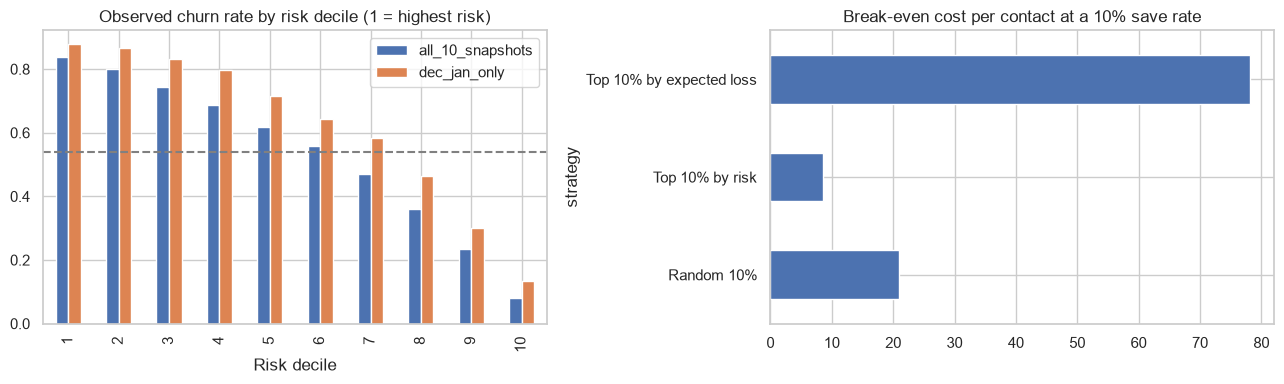

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
rates.plot(kind="bar", ax=ax[0])
ax[0].axhline(lr["churned"].mean(), color="gray", linestyle="--")
ax[0].set_title("Observed churn rate by risk decile (1 = highest risk)")
ax[0].set_xlabel("Risk decile")
breakeven["save 10%"].plot(kind="barh", ax=ax[1])
ax[1].set_title("Break-even cost per contact at a 10% save rate")
plt.tight_layout()
plt.show()